[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/makaroveo/itmo-python-data-analysis/blob/main/lab02_03/lab02_03_kmeans_dbscan.ipynb)

# Лабораторные работы 2 и 3. Методы k-средних и DBSCAN

Вариант 2: Economics of Cities. Макаров Семён, ИСУ 335173.

Задача: разбить 48 городов на группы методами k-means (ЛР2) и DBSCAN (ЛР3), обосновать число кластеров и параметры каждого метода заново, интерпретировать группы и шум и сравнить результаты всех трёх лабораторных (Ward, k-means, DBSCAN).

## 1. Данные и подготовка

Набор данных тот же, что в ЛР1: 48 городов мира 1991 года, признаки Work (рабочие часы), Price (индекс цен, Цюрих = 100) и Salary (индекс часовой зарплаты после налогов, Цюрих = 100). Подробный разведочный анализ сделан в ЛР1, здесь повторяю только загрузку, обработку пропусков и стандартизацию, чтобы результаты всех трёх методов были сопоставимы.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.preprocessing import MinMaxScaler, StandardScaler

FEATURES = ['Work', 'Price', 'Salary']
# цвета кластеров 1, 2 и шума (-1) на всех графиках
COLORS = {-1: '#9a9a9a', 1: '#1f77b4', 2: '#ff7f0e'}
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.25})


def find_csv(name='Econom_Cities_data.csv'):
    # локально файл лежит рядом с ноутбуком
    if Path(name).exists():
        return Path(name)
    if 'google.colab' not in sys.modules:
        raise FileNotFoundError(f'Не нашёл {name}: положите его рядом с ноутбуком')
    # в Colab файла нет, поэтому открываю диалог загрузки
    from google.colab import files
    return Path(next(iter(files.upload())))


def load_cities(path):
    # разделитель ';', десятичная запятая; -9999 в файле означает пропуск
    X = pd.read_csv(path, sep=';', decimal=',', index_col='City')
    return X[FEATURES].replace(-9999, np.nan)


X = load_cities(find_csv())
filled = SimpleImputer(strategy='median').fit_transform(X)
Z = StandardScaler().fit_transform(filled)

print('Городов:', len(X), '| пропусков:', X.isna().sum().to_dict())
print('Доля в общей дисперсии без масштабирования, %:')
print(pd.Series(filled.var(axis=0) / filled.var(axis=0).sum() * 100, index=FEATURES).round(1))

Городов: 48 | пропусков: {'Work': 2, 'Price': 0, 'Salary': 2}
Доля в общей дисперсии без масштабирования, %:
Work      96.5
Price      1.6
Salary     1.9
dtype: float64


Пропуски (`-9999` у Cairo и Jakarta в Work и Salary) заменены медианой; исходная таблица `X` с `NaN` сохранена отдельно для расчёта средних и медиан по реальным значениям.

Нужно ли стандартизовать? Да: на Work приходится 96.5 % общей дисперсии (разброс ~174 часа против ~22–25 у индексов). Без масштабирования k-means делил бы города почти только по часам работы, а в DBSCAN один радиус `eps` измерял бы одновременно часы и пункты индекса. Перевожу признаки в z-оценки (`Z`, среднее 0 и стандартное отклонение 1).

---
# Часть 1. ЛР2. Метод k-средних (k-means)

## 2.1. Алгоритм и сетка по k

k-means ищет k центров так, чтобы сумма квадратов расстояний от городов до центра своего кластера (критерий W, в scikit-learn `inertia_`) была минимальной. Алгоритм повторяет два шага: относит каждый город к ближайшему центру, затем переносит центр в среднее своих городов. Так он приходит к локальному минимуму, зависящему от стартовых центров. Поэтому задаю:

* `init='k-means++'`: начальные центры выбираются подальше друг от друга;
* `n_init=50`: 50 запусков с разных стартов, берётся лучший по W;
* `max_iter=300`: предел числа итераций в одном запуске;
* `random_state=42`: для воспроизводимости.

Число кластеров k обосновываю заново, не перенося его из ЛР1.

Что показывают столбцы таблицы ниже:
* `inertia` ($W$): сумма квадратов расстояний от городов до центров их кластеров (меньше — плотнее, всегда убывает с ростом $k$);
* `падение inertia, %`: на сколько процентов уменьшилась $W$ при шаге от $k-1$ к $k$ — помогает увидеть излом «осыпи»;
* `silhouette` (от $-1$ до $1$, выше — лучше): насколько объекты ближе к своему кластеру, чем к соседнему;
* `CH` (Calinski–Harabasz, выше — лучше): отношение межкластерного разброса к внутрикластерному;
* `DB` (Davies–Bouldin, ниже — лучше): отношение размеров кластеров к расстоянию между ними;
* `min_size`: размер самого маленького кластера (контроль одноточечных кластеров).

In [2]:
from sklearn.cluster import KMeans


def quality(Z, labels):
    return {'silhouette': silhouette_score(Z, labels),
            'CH': calinski_harabasz_score(Z, labels),
            'DB': davies_bouldin_score(Z, labels)}


def run_kmeans(Z, k, init='k-means++', n_init=50, seed=42):
    return KMeans(n_clusters=k, init=init, n_init=n_init, max_iter=300, random_state=seed).fit(Z)


km_rows = [{'k': 1, 'inertia': run_kmeans(Z, 1).inertia_}]  # k = 1 нужен для масштаба осыпи
for k in range(2, 9):
    m = run_kmeans(Z, k)
    km_rows.append({'k': k, 'inertia': m.inertia_, **quality(Z, m.labels_),
                    'min_size': np.bincount(m.labels_).min()})
km_grid = pd.DataFrame(km_rows)
km_grid['падение inertia, %'] = (-km_grid.inertia.pct_change() * 100).round(1)
km_grid.set_index('k').round(3)

,inertia,silhouette,CH,DB,min_size,"падение inertia, %"
k,,,,,,
1,144.000,NaN,NaN,NaN,NaN,NaN
2,66.411,0.454,53.742,0.844,23.0,53.9
3,50.470,0.383,41.697,0.936,10.0,24.0
4,38.938,0.358,39.573,1.087,6.0,22.8
5,31.142,0.371,38.958,0.943,6.0,20.0
6,25.812,0.365,38.462,0.964,4.0,17.1
7,21.298,0.381,39.369,0.866,3.0,17.5
8,17.780,0.388,40.566,0.794,2.0,16.5


### Памятка: почему `init='k-means++'`, а не `random`

* **`init='random'`:** все $k$ стартовых центров выбираются случайно. Если два центра попадают в одно скопление, они делят его пополам, а два других скопления могут склеиться — алгоритм застревает в локальном минимуме.
* **`init='k-means++'`:** первый центр выбирается случайно, а каждый следующий — с вероятностью $P(x) \propto D(x)^2$, где $D(x)$ — расстояние до ближайшего уже выбранного центра. Это разносит старты по разным областям данных, но не привязывает центры жёстко к одиночным выбросам. На примере ниже видно, как удачный старт снижает ошибку $W$.

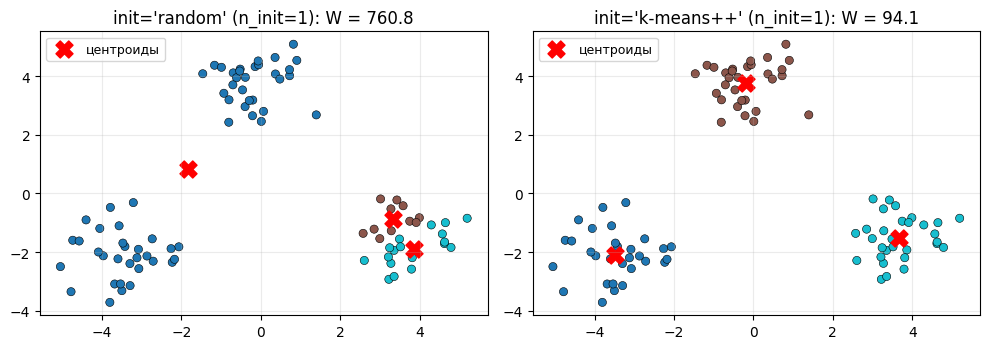

In [3]:
from sklearn.datasets import make_blobs

X_demo, _ = make_blobs(n_samples=90, centers=[[-3.5, -2.0], [3.5, -1.5], [0.0, 3.8]],
                       cluster_std=0.75, random_state=7)
km_rand = KMeans(n_clusters=3, init='random', n_init=1, random_state=9).fit(X_demo)
km_pp = KMeans(n_clusters=3, init='k-means++', n_init=1, random_state=7).fit(X_demo)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, model, title in [(axes[0], km_rand, f"init='random' (n_init=1): W = {km_rand.inertia_:.1f}"),
                         (axes[1], km_pp, f"init='k-means++' (n_init=1): W = {km_pp.inertia_:.1f}")]:
    ax.scatter(X_demo[:, 0], X_demo[:, 1], c=model.labels_, cmap='tab10', s=35, edgecolors='k', linewidths=0.4)
    ax.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], c='red', marker='X', s=150, label='центроиды')
    ax.set_title(title)
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 2.2. Выбор числа кластеров

Главный инструмент: «каменистая осыпь» W(k). W убывает при любом росте k (при k = 48 оно станет нулём), поэтому ищу излом: точку, после которой новый кластер почти ничего не даёт.

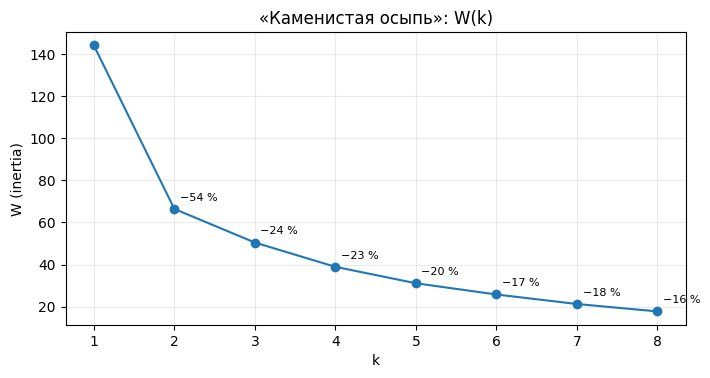

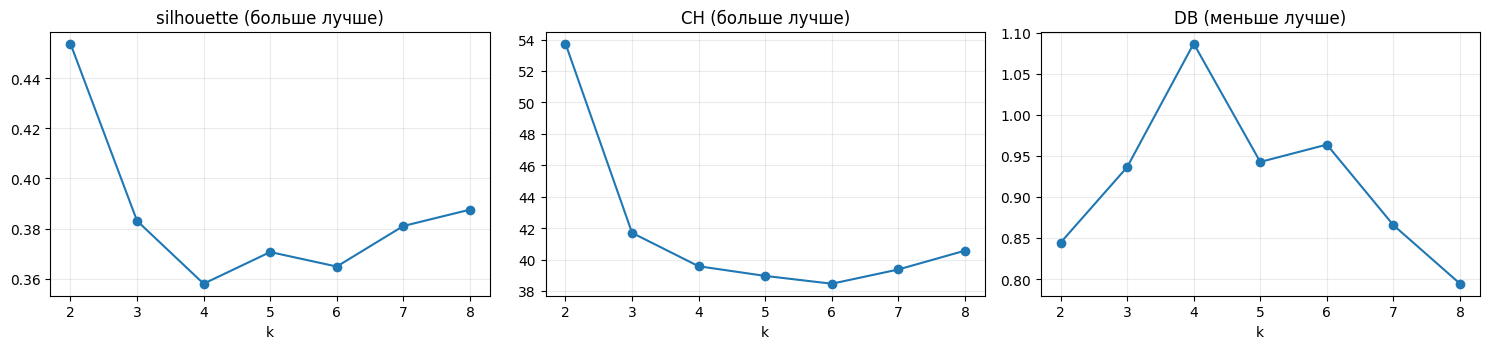

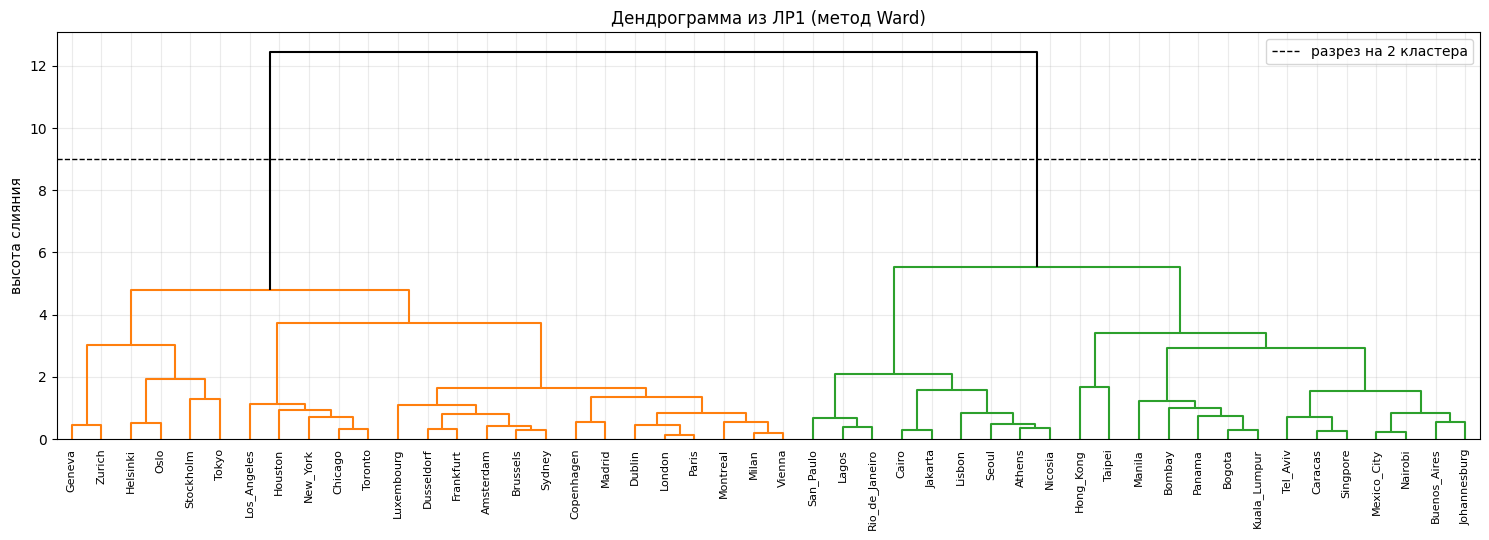

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(km_grid.k, km_grid.inertia, 'o-')
for k, w, drop in km_grid[['k', 'inertia', 'падение inertia, %']].itertuples(index=False):
    if k > 1:
        ax.annotate(f'−{drop:.0f} %', (k, w), xytext=(4, 6), textcoords='offset points', fontsize=8)
ax.set(title='«Каменистая осыпь»: W(k)', xlabel='k', ylabel='W (inertia)', xticks=km_grid.k)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, note in zip(axes, ['silhouette', 'CH', 'DB'], ['больше лучше', 'больше лучше', 'меньше лучше']):
    ax.plot(km_grid.k, km_grid[col], 'o-')
    ax.set(title=f'{col} ({note})', xlabel='k')
plt.tight_layout()
plt.show()

from scipy.cluster.hierarchy import dendrogram, linkage

Lw = linkage(Z, method='ward')
threshold = (Lw[-1, 2] + Lw[-2, 2]) / 2  # ориентир из ЛР1: разрез на 2 кластера
fig, ax = plt.subplots(figsize=(15, 5.5))
dendrogram(Lw, labels=X.index.tolist(), leaf_rotation=90, leaf_font_size=8,
           color_threshold=threshold, above_threshold_color='black', ax=ax)
ax.axhline(threshold, color='black', ls='--', lw=1, label='разрез на 2 кластера')
ax.set(title='Дендрограмма из ЛР1 (метод Ward)', ylabel='высота слияния')
ax.legend()
plt.tight_layout()
plt.show()

Излом осыпи приходится на k = 2: переход от одного кластера к двум уменьшает W со 144 до 66.4 (на 54 %), дальше каждый новый кластер даёт только 24, 23, 20, 17 %. Кривая после k = 2 убывает ровно, второго излома нет.

Формальные метрики использую как дополнительный аргумент:

* silhouette максимален при k = 2 (0.454);
* Calinski-Harabasz (CH) тоже максимален при k = 2 (53.7);
* Davies-Bouldin (DB) чуть лучше только при k = 8 (0.794), где есть кластеры из двух городов.

Силуэт я не делаю главным критерием: он часто даёт максимум при двух кластерах и отвечает только на вопрос о компактности и разделённости, а не о содержательной пользе разбиения. Здесь он согласуется с осыпью.

Два кластера могут показаться грубым делением, поэтому проверю, что даёт третий кластер.

In [5]:
def relabel_by_salary(labels, X):
    # нумерую кластеры 1, 2, ... по убыванию медианной зарплаты; шум (-1) остаётся -1
    labels = np.asarray(labels)
    groups = sorted(set(labels) - {-1}, key=lambda g: -X.Salary[labels == g].median())
    new = {g: i + 1 for i, g in enumerate(groups)}
    return np.array([new.get(g, -1) for g in labels])


def profile(X, labels):
    # размер, средние и медианы по кластерам в исходных единицах; пропуски (NaN) в расчёт не попадают
    g = X.groupby(labels)
    return pd.concat([g.size().rename('городов'), g.mean().add_suffix(' среднее'),
                      g.median().add_suffix(' медиана')], axis=1).rename_axis('кластер')


K = 2
km_model = run_kmeans(Z, K)
km_labels = relabel_by_salary(km_model.labels_, X)
km_scores = quality(Z, km_labels)
print(f'k = 2: W = {km_model.inertia_:.3f}', {m: round(v, 3) for m, v in km_scores.items()})

km_labels3 = relabel_by_salary(run_kmeans(Z, 3).labels_, X)
display(pd.crosstab(pd.Series(km_labels, name='k = 2'), pd.Series(km_labels3, name='k = 3')))
display(profile(X, km_labels3).round(1))
for g in (2, 3):
    print(f'Кластер {g} при k = 3:', ', '.join(X.index[km_labels3 == g]))

k = 2: W = 66.411 {'silhouette': 0.454, 'CH': 53.742, 'DB': 0.844}


k = 3,1,2,3
k = 2,,,
1,25,0,0
2,0,10,13


,городов,Work среднее,Price среднее,Salary среднее,Work медиана,Price медиана,Salary медиана
кластер,,,,,,,
1,25,1789.2,85.0,59.0,1768.0,79.8,58.2
2,10,2133.5,54.2,16.1,2111.5,55.1,12.6
3,13,1855.5,49.2,16.6,1842.0,48.9,12.5


Кластер 2 при k = 3: Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lumpur, Manila, Panama, Singpore, Taipei, Tel_Aviv
Кластер 3 при k = 3: Athens, Buenos_Aires, Cairo, Jakarta, Johannesburg, Lagos, Lisbon, Mexico_City, Nairobi, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul


При k = 3 первый кластер (25 городов) не меняется, а второй делится на две части:

* 10 городов с самым длинным рабочим годом, в среднем 2 134 часа (Hong_Kong, Manila, Taipei, Bombay, Bogota, Singpore и др.);
* 13 городов, где работают меньше, в среднем 1 856 часов (Athens, Lisbon, Seoul, Mexico_City, Nairobi и др.).

Средние цены (54 и 49) и зарплаты (16 и 17) у этих частей почти одинаковые. Третий кластер уменьшает W всего на 24 % (с 66.4 до 50.5), излома на осыпи нет. Оставив два кластера, я теряю только детализацию по часам работы среди небогатых городов, а главное различие по ценам и зарплатам сохраняется. Поэтому основным решением беру k = 2, а k = 3 считаю возможной детализацией.

## 2.3. Интерпретация кластеров k-means

В первой таблице показаны центры кластеров k-means (средние по всем городам с заполненными пропусками). Во второй таблице средние и медианы посчитаны только по реальным значениям, без заполненных Work и Salary у Cairo и Jakarta, поэтому для второго кластера они немного отличаются от центров.

,Work,Price,Salary
кластер,,,
1,1789.2,85.0,59.0
2,1975.8,51.3,18.7


,городов,Work среднее,Price среднее,Salary среднее,Work медиана,Price медиана,Salary медиана
кластер,,,,,,,
1,25,1789.2,85.0,59.0,1768.0,79.8,58.2
2,23,1987.9,51.3,16.3,1971.0,49.2,12.5


Кластер 1: Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
Кластер 2: Athens, Bogota, Bombay, Buenos_Aires, Cairo, Caracas, Hong_Kong, Jakarta, Johannesburg, Kuala_Lumpur, Lagos, Lisbon, Manila, Mexico_City, Nairobi, Nicosia, Panama, Rio_de_Janeiro, San_Paulo, Seoul, Singpore, Taipei, Tel_Aviv


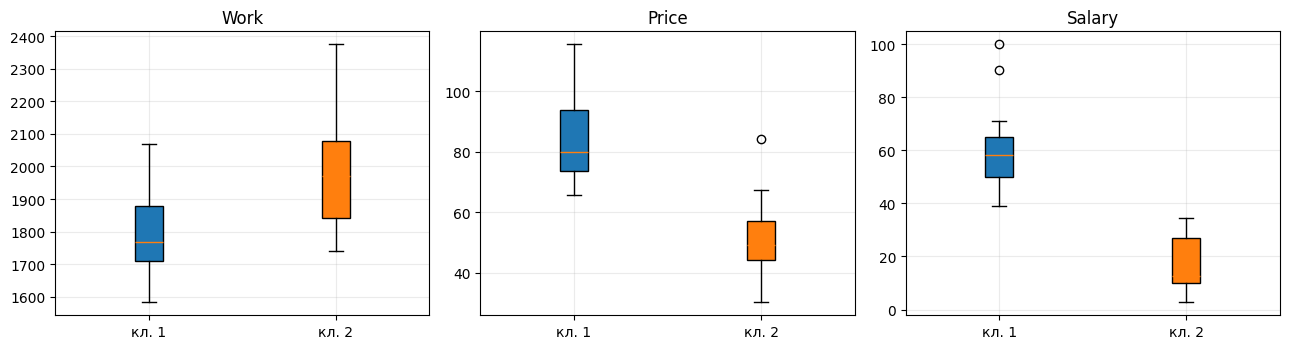

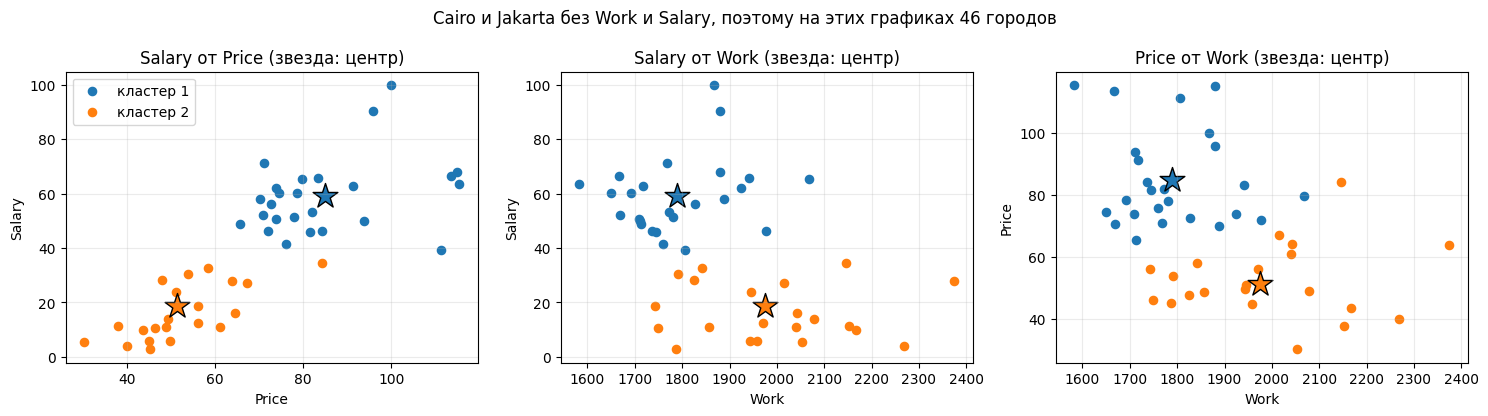

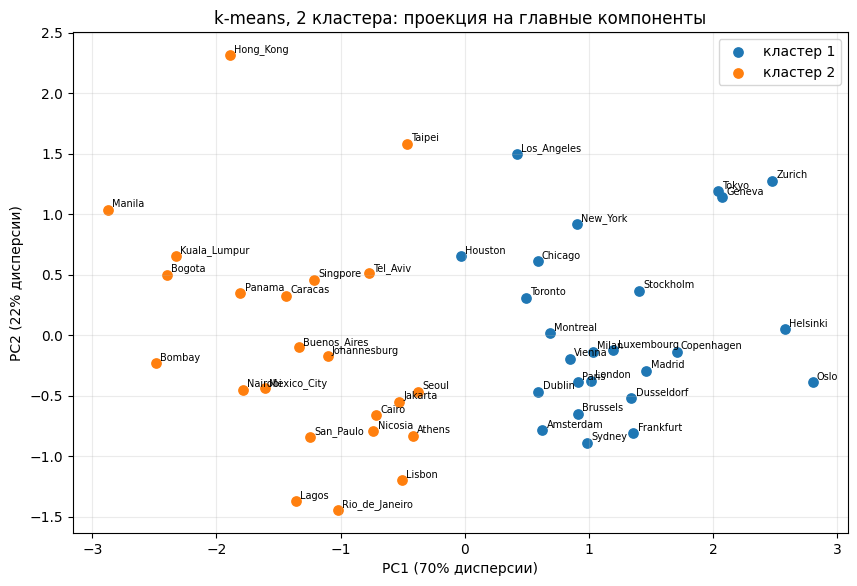

In [6]:
def color(g):
    return COLORS.get(g, f'C{g - 1}')


def plot_boxes(X, labels):
    # ящики с усами по группам; заполненные пропуски не рисую
    axes = plt.subplots(1, 3, figsize=(13, 3.6))[1]
    groups = sorted(set(labels), key=lambda g: (g == -1, g))
    for ax, f in zip(axes, FEATURES):
        box = ax.boxplot([X.loc[labels == g, f].dropna() for g in groups], patch_artist=True)
        ax.set_xticks(range(1, len(groups) + 1), ['шум' if g == -1 else f'кл. {g}' for g in groups])
        for patch, g in zip(box['boxes'], groups):
            patch.set_facecolor(color(g))
        ax.set(title=f)
    plt.tight_layout()


def plot_pca(Z, labels, names, title, ax=None):
    # PCA только для рисунка: сама кластеризация идёт по всем трём признакам
    pca = PCA(n_components=2).fit(Z)
    P = pca.transform(Z)
    ax = ax or plt.subplots(figsize=(10, 6.5))[1]
    for g in sorted(set(labels)):
        m = labels == g
        ax.scatter(P[m, 0], P[m, 1], s=45, c=color(g), marker='x' if g == -1 else 'o',
                   label='шум' if g == -1 else f'кластер {g}')
    for (x, y), city in zip(P, names):
        ax.annotate(city, (x, y), fontsize=7, xytext=(3, 2), textcoords='offset points')
    share = pca.explained_variance_ratio_
    ax.set(xlabel=f'PC1 ({share[0]:.0%} дисперсии)', ylabel=f'PC2 ({share[1]:.0%} дисперсии)', title=title)
    ax.legend()
    return P


centers = pd.DataFrame(filled, columns=FEATURES).groupby(km_labels).mean()
display(centers.rename_axis('кластер').round(1))
display(profile(X, km_labels).round(1))
for g in sorted(set(km_labels)):
    print(f'Кластер {g}:', ', '.join(X.index[km_labels == g]))

plot_boxes(X, km_labels)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (fx, fy) in zip(axes, [('Price', 'Salary'), ('Work', 'Salary'), ('Work', 'Price')]):
    for g in sorted(set(km_labels)):
        m = km_labels == g
        ax.scatter(X.loc[m, fx], X.loc[m, fy], c=color(g), label=f'кластер {g}', s=35)
        ax.scatter(centers.loc[g, fx], centers.loc[g, fy], c=color(g), marker='*', s=350, edgecolor='black')
    ax.set(xlabel=fx, ylabel=fy, title=f'{fy} от {fx} (звезда: центр)')
fig.suptitle('Cairo и Jakarta без Work и Salary, поэтому на этих графиках 46 городов')
axes[0].legend()
plt.tight_layout()
plt.show()

P = plot_pca(Z, km_labels, X.index, 'k-means, 2 кластера: проекция на главные компоненты')
plt.show()

**Кластер 1 (25 городов): дорогие города с высокими зарплатами и коротким рабочим годом.** В среднем зарплата 59 % от цюрихской, цены 85 %, 1 789 часов. Западная и Северная Европа, США и Канада, Tokyo, Sydney: Paris, London, New_York, Toronto, Oslo.

**Кластер 2 (23 города): цены заметно ниже, зарплаты в разы ниже, работают больше.** В среднем зарплата 16 %, цены 51 %, 1 988 часов. Латинская Америка, Азия, Африка, Ближний Восток и Athens, Lisbon, Nicosia: Bogota, Bombay, Manila, Nairobi.

Сильнее всего группы расходятся по зарплатам (средние 59 против 16, медианы 58.2 против 12.5) и ценам (85 против 51): в плоскости Price и Salary их можно разделить почти прямой линией. По Work разница около 200 часов, и ящики с усами частично перекрываются. Две главные компоненты сохраняют 92 % дисперсии.

## 2.4. Зачем нужно много запусков (`n_init = 50`)

Проверяю, насколько надёжен один запуск (`n_init = 1`): для k от 2 до 5 делаю по 100 запусков со случайными стартами и с `k-means++` и сравниваю с лучшей W среди всех 200 запусков.

In [7]:
init_rows = []
for k in [2, 3, 4, 5]:
    runs = {init: np.array([run_kmeans(Z, k, init=init, n_init=1, seed=s).inertia_ for s in range(100)])
            for init in ['random', 'k-means++']}
    best = min(r.min() for r in runs.values())
    for init, inertia in runs.items():
        init_rows.append({'k': k, 'инициализация': init, 'общий минимум W': best,
                          'доля запусков с общим минимумом': np.isclose(inertia, best).mean(),
                          'лучшая W серии': inertia.min(), 'худшая W серии': inertia.max()})
pd.DataFrame(init_rows).round(3)

,k,инициализация,общий минимум W,доля запусков с общим минимумом,лучшая W серии,худшая W серии
0,2,random,66.411,0.61,66.411,66.572
1,2,k-means++,66.411,0.65,66.411,66.572
2,3,random,50.470,0.18,50.470,58.283
3,3,k-means++,50.470,0.15,50.470,58.116
4,4,random,38.938,0.00,39.001,50.365
5,4,k-means++,38.938,0.02,38.938,49.568
6,5,random,31.031,0.02,31.031,47.663
7,5,k-means++,31.031,0.00,31.142,42.833


При k = 2 один запуск находит общий минимум примерно в 60 % случаев, при k = 3 в 15–18 %, а при k = 4–5 почти никогда. Алгоритм застревает в локальных минимумах, и `k-means++` спасает от этого не полностью: при k = 5 общий минимум (31.03) нашли только 2 из 100 случайных стартов, а лучший из 100 стартов `k-means++` остановился на 31.14. Для выбранного k = 2 один запуск промахивается в ~40 % случаев, поэтому `n_init = 50` ставится с запасом.

## 2.5. Проверка стандартизации для k-means

In [8]:
minmax = MinMaxScaler().fit_transform(filled)  # каждый признак в [0, 1]
pd.Series({
    'без масштабирования': adjusted_rand_score(km_labels, run_kmeans(filled, K).labels_),
    'приведение к [0, 1]': adjusted_rand_score(km_labels, run_kmeans(minmax, K).labels_),
}, name='ARI с решением k-means на z-оценках').round(3).to_frame()

,ARI с решением k-means на z-оценках
без масштабирования,0.194
"приведение к [0, 1]",1.000


Без масштабирования разбиение получается почти другим (ARI 0.194): k-means режет города в основном по часам работы. Приведение к [0, 1] даёт те же два кластера (ARI = 1), так что от способа стандартизации решение k-means не зависит.

## 2.6. Сколько итераций нужно в одном запуске (`max_iter`)

Проверяю, сколько шагов до сходимости (`n_iter_`) реально делает один запуск `k-means` (`n_init = 1`) при `k` от 2 до 5, и какой минимальный `max_iter` нужен для `k = 2`, чтобы получить тот же минимум W = 66.411, что и при `max_iter = 300`.

In [9]:
iter_rows = []
for k in [2, 3, 4, 5]:
    for init in ['random', 'k-means++']:
        iters = np.array([KMeans(n_clusters=k, init=init, n_init=1, max_iter=300, random_state=s).fit(Z).n_iter_
                          for s in range(100)])
        iter_rows.append({'k': k, 'инициализация': init, 'мин': iters.min(),
                          'медиана': np.median(iters), 'среднее': iters.mean(), 'макс': iters.max()})
display(pd.DataFrame(iter_rows).round(2))

for m in [1, 2, 3, 5, 10]:
    km_m = KMeans(n_clusters=2, init='k-means++', n_init=50, max_iter=m, random_state=42).fit(Z)
    print(f'max_iter = {m:2d}: W = {km_m.inertia_:.3f}, совпало с max_iter=300: {np.isclose(km_m.inertia_, km_model.inertia_)}')

,k,инициализация,мин,медиана,среднее,макс
0,2,random,2,4.0,4.16,7
1,2,k-means++,2,3.0,3.58,9
2,3,random,2,4.0,4.54,8
3,3,k-means++,2,4.0,3.91,10
4,4,random,2,5.0,5.00,10
5,4,k-means++,2,4.0,3.97,11
6,5,random,2,5.0,5.54,12
7,5,k-means++,2,4.0,4.01,9


max_iter =  1: W = 66.411, совпало с max_iter=300: True
max_iter =  2: W = 66.411, совпало с max_iter=300: True
max_iter =  3: W = 66.411, совпало с max_iter=300: True
max_iter =  5: W = 66.411, совпало с max_iter=300: True
max_iter = 10: W = 66.411, совпало с max_iter=300: True


В среднем на этих данных один запуск сходится за 3.6–5.5 итераций, а максимум по всем 800 одиночным запускам составил 12 итераций (при `k = 2` с `k-means++` — до 9). При `n_init = 50` для `k = 2` уже на `max_iter = 1` один из 50 стартов даёт точный минимум W = 66.411. Значение `max_iter = 300` по умолчанию не тормозит работу: алгоритм всё равно останавливается сразу после сходимости, а 300 служит только верхним ограничением.

**Как алгоритм понимает, что пора остановиться:** в `KMeans` есть параметр `tol` (по умолчанию `1e-4`). На каждом шаге считается сумма квадратов сдвигов всех центров $\|\mu_{\text{нов}} - \mu_{\text{стар}}\|_F^2$. Когда этот сдвиг становится меньше `tol` (с поправкой на масштаб данных) — на 48 городах центры просто перестают меняться, и сдвиг падает до нуля — цикл досрочно завершается.

---
# Часть 2. ЛР3. Метод DBSCAN

## 3.1. Как работает DBSCAN и стратегия подбора параметров

* **Окрестность города:** все города на евклидовом расстоянии не больше `eps` в z-оценках.
* **Ядерный город:** в его окрестности не меньше `M` (`min_samples`) городов, считая его самого (так в scikit-learn).
* **Граничный город:** сам не ядерный, но лежит в окрестности какого-то ядерного.
* **Шум (метка −1):** ни то, ни другое. Шум считаю фоном и отдельным кластером не называю.

Число кластеров здесь не задаётся заранее, оно следует из `eps` и `M`. Готового рецепта для них нет: эвристики (`M ≥ D + 1`, `M ≈ 2·D` и максимум силуэта) ненадёжны. Поэтому `M = 2·D = 6` беру только как стартовую точку. Решение принимаю по размерам кластеров, числу шумовых городов, устойчивости при соседних параметрах и разумности состава, меняя по одному параметру за раз.

Строю сетку: `M` от 3 до 9, `eps` от 0.30 до 1.30 с шагом 0.05. Для ориентира отмечаю, совпадают ли найденные группы на городах вне шума с решением Ward из ЛР1.

In [10]:
from scipy.cluster.hierarchy import fcluster, linkage
from sklearn.cluster import DBSCAN


def run_dbscan(Z, eps, min_samples):
    model = DBSCAN(eps=eps, min_samples=min_samples).fit(Z)
    core = np.zeros(len(Z), bool)
    core[model.core_sample_indices_] = True
    return model.labels_, core


def describe_dbscan(Z, eps, min_samples, ref_labels):
    lab = relabel_by_salary(run_dbscan(Z, eps, min_samples)[0], X)
    clustered = lab != -1
    sizes = np.bincount(lab[clustered])[1:]
    return {'clusters': len(sizes), 'noise': int((~clustered).sum()), 'min_size': sizes.min() if len(sizes) else 0,
            # silhouette имеет смысл только при 2+ кластерах; считаю по городам без шума
            'silhouette': silhouette_score(Z[clustered], lab[clustered]) if len(sizes) >= 2 else np.nan,
            'размеры': ' / '.join(map(str, sizes)),
            'как Ward': len(sizes) == 2 and adjusted_rand_score(ref_labels[clustered], lab[clustered]) == 1}


ward_tree = linkage(Z, 'ward')
ward_labels = relabel_by_salary(fcluster(ward_tree, t=2, criterion='maxclust'), X)  # решение ЛР1
db_grid = pd.DataFrame([{'min_samples': ms, 'eps': eps, **describe_dbscan(Z, eps, ms, ward_labels)}
                        for ms in range(3, 10) for eps in np.round(np.arange(0.30, 1.31, 0.05), 2)])

## 3.2. Пошаговый подбор `eps` и `M`

### Шаг 1. `M = 6`, меняю `eps`

In [11]:
MIN_SAMPLES = 6
step1 = db_grid[(db_grid.min_samples == MIN_SAMPLES) & db_grid.eps.between(0.45, 1.1)].set_index('eps')
step1[['clusters', 'размеры', 'noise', 'как Ward', 'silhouette']].round(3).T

eps,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,1.00,1.05,1.10
clusters,1,1,1,2,2,2,3,2,2,2,2,1,1,1
размеры,6,11,12,12 / 6,13 / 6,13 / 6,16 / 8 / 9,18 / 17,18 / 19,18 / 20,19 / 20,39,39,41
noise,42,37,36,30,29,29,15,13,11,10,9,9,9,7
как Ward,False,False,False,True,True,True,False,True,True,True,True,False,False,False
silhouette,NaN,NaN,NaN,0.728,0.724,0.724,0.491,0.52,0.5,0.501,0.49,NaN,NaN,NaN


При `M = 6` видны четыре режима:

* `eps` до 0.55: радиус слишком мал. При 0.45–0.55 одна группа из 6–12 городов, остальные 36–42 в шуме.
* `eps` 0.60–0.70: две маленькие плотные группы (12–13 и 6 городов), но 29–30 городов (60–63 %) в шуме, радиус маловат. При 0.75 появляется третья группа (16 / 8 / 9).
* `eps` 0.80–0.95: **плато**. Стабильно два кластера (18 / 17 → 18 / 19 → 18 / 20 → 19 / 20), шум плавно уменьшается с 13 до 9, а на городах вне шума кластеры совпадают с Ward.
* `eps` от 1.0: обе группы сливаются через промежуточные города в один кластер из 39 и больше городов.

Здесь наглядно видно, почему нельзя выбирать параметры по максимуму силуэта: он максимален при `eps = 0.60` (0.728) и 0.65–0.70 (0.724) только потому, что больше 60 % городов выброшены в шум. На плато силуэт около 0.50.

Беру `eps` из середины плато: **0.9** (2 кластера по 18 и 20 городов и 10 городов шума, 21 %).

### Шаг 2. `eps = 0.9`, меняю `M`

In [12]:
EPS = 0.9
step2 = db_grid[db_grid.eps == EPS].set_index('min_samples')
step2[['clusters', 'размеры', 'noise', 'как Ward']].T

min_samples,3,4,5,6,7,8,9
clusters,1,1,2,2,2,2,2
размеры,40,40,18 / 21,18 / 20,18 / 20,18 / 19,16 / 19
noise,8,8,9,10,10,11,13
как Ward,False,False,True,True,True,True,True


При `eps = 0.9`:

* `M = 3–4`: порог низкий, обе группы соединяются через цепочку промежуточных городов в один кластер из 40 городов.
* `M = 5–8`: стабильно два кластера, на городах вне шума совпадающие с Ward (18 / 21, 18 / 20, 18 / 20, 18 / 19), шум от 9 до 11 городов.
* `M = 9`: два кластера ещё держатся, но шум растёт до 13.

`M = 6` лежит внутри устойчивого диапазона 5–8. Стартовая точка `2·D` оказалась удачной, но обоснованием служит именно поведение при соседних `M`, а не сама формула.

### Шаг 3. Вся сетка `(M, eps)`

В каждой клетке число кластеров / число шумовых городов; `✓` отмечает пары, где на городах вне шума получаются те же две группы, что у Ward.

In [13]:
cells = db_grid[db_grid.eps.between(0.55, 1.05)].assign(
    cell=lambda g: g.clusters.astype(str) + ' / ' + g.noise.astype(str) + np.where(g['как Ward'], ' ✓', ''))
cells.pivot(index='min_samples', columns='eps', values='cell')

eps,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,1.00,1.05
min_samples,,,,,,,,,,,
3,3 / 24,2 / 18 ✓,2 / 15 ✓,2 / 12 ✓,2 / 9 ✓,2 / 8 ✓,2 / 8 ✓,1 / 8,1 / 8,1 / 8,1 / 8
4,1 / 36,3 / 23,3 / 17,3 / 13,2 / 10 ✓,2 / 9 ✓,2 / 8 ✓,1 / 8,1 / 8,1 / 8,1 / 8
5,1 / 36,2 / 30 ✓,2 / 27 ✓,3 / 24,3 / 12,2 / 10 ✓,2 / 9 ✓,2 / 9 ✓,2 / 8 ✓,1 / 8,1 / 8
6,1 / 36,2 / 30 ✓,2 / 29 ✓,2 / 29 ✓,3 / 15,2 / 13 ✓,2 / 11 ✓,2 / 10 ✓,2 / 9 ✓,1 / 9,1 / 9
7,1 / 36,1 / 36,1 / 35,1 / 35,3 / 19,2 / 17 ✓,2 / 13 ✓,2 / 10 ✓,2 / 10 ✓,2 / 9 ✓,1 / 9
8,1 / 39,1 / 37,1 / 37,1 / 35,1 / 34,2 / 21 ✓,2 / 15 ✓,2 / 11 ✓,2 / 10 ✓,2 / 10 ✓,1 / 9
9,1 / 39,1 / 38,1 / 38,1 / 35,1 / 34,1 / 32,2 / 19 ✓,2 / 13 ✓,2 / 12 ✓,2 / 10 ✓,2 / 9


При любом `M` от 3 до 9 есть своё плато с теми же двумя группами. Чем больше `M`, тем правее плато: при `M = 3` это `eps` 0.60–0.85, при `M = 8` уже 0.80–1.00. Выбранная пара `(0.9, 6)` лежит в середине широкой области, где две группы сохраняются, а от точного значения параметров зависит только состав пограничного шума.

### Визуальная проверка: графики k-расстояний и цветная 2D тепловая карта

* **Графики k-расстояний (`M = 2..6`):** города отсортированы по расстоянию до $M$-го соседа (считая сам город). При малом `M` видны отдельные выбросы, при `M = 6` перегиб отделяет уже всю группу разреженных городов.
* **Тепловая карта (`eps × M`):** цвет показывает число шумовых городов, подпись в клетке — `кластеры / шум` (`✓` — совпадение с Ward вне шума), красной рамкой выделена выбранная пара `(0.9, 6)`.

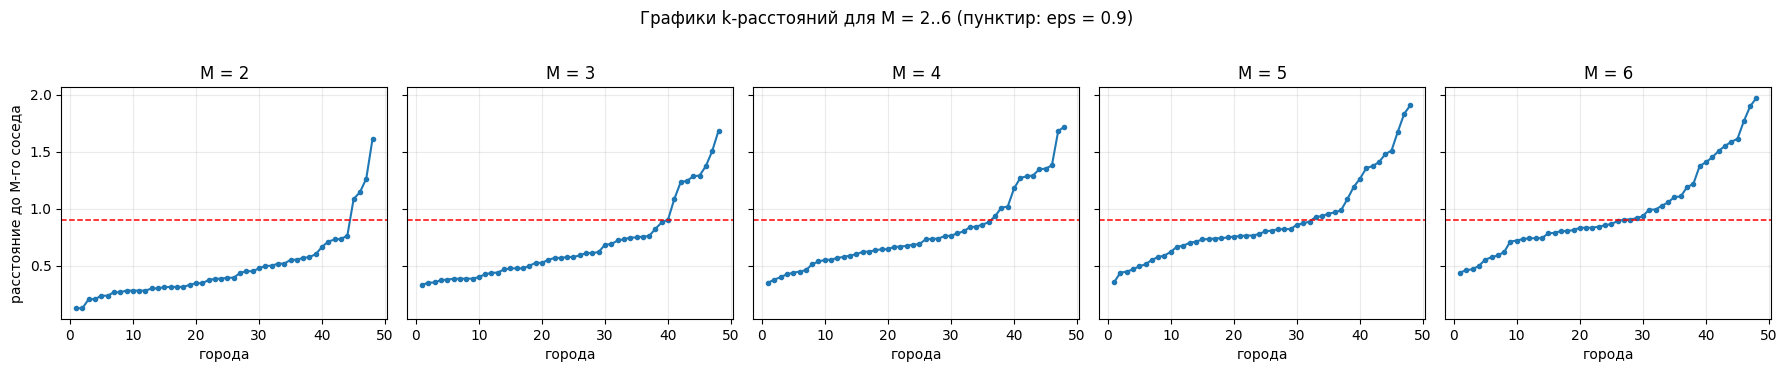

In [14]:
from sklearn.neighbors import NearestNeighbors

fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), sharey=True)
for ax, m in zip(axes, [2, 3, 4, 5, 6]):
    k_dist = np.sort(NearestNeighbors(n_neighbors=m).fit(Z).kneighbors(Z)[0][:, -1])
    ax.plot(range(1, len(k_dist) + 1), k_dist, 'o-', ms=3)
    ax.axhline(EPS, color='red', ls='--', lw=1.1)
    ax.set(title=f'M = {m}', xlabel='города')
axes[0].set_ylabel('расстояние до M-го соседа')
fig.suptitle(f'Графики k-расстояний для M = 2..6 (пунктир: eps = {EPS})', y=1.02)
plt.tight_layout()
plt.show()

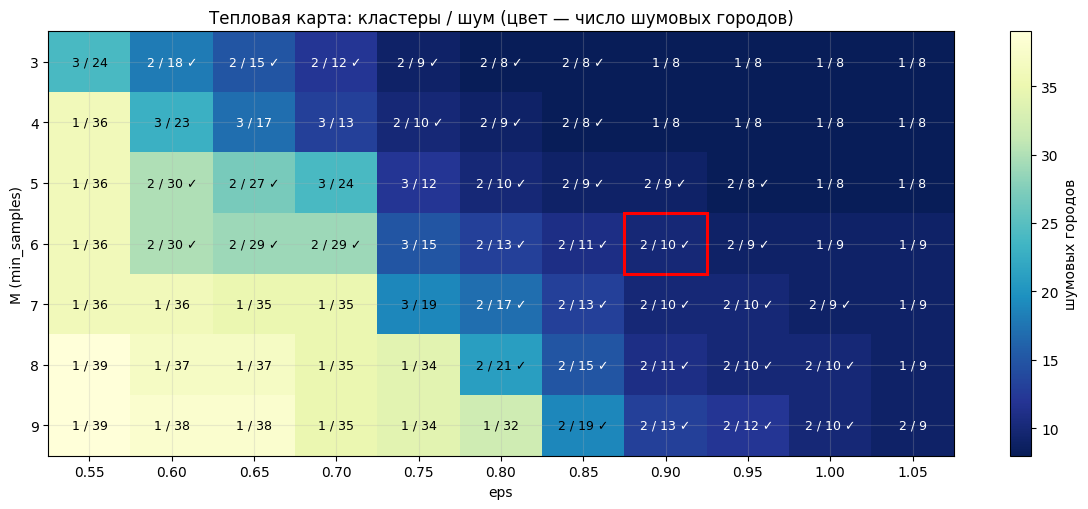

In [15]:
from matplotlib.patches import Rectangle

piv_noise = cells.pivot(index='min_samples', columns='eps', values='noise')
piv_text = cells.pivot(index='min_samples', columns='eps', values='cell')

fig, ax = plt.subplots(figsize=(12, 5.2))
im = ax.imshow(piv_noise.values, cmap='YlGnBu_r', aspect='auto')
ax.set_xticks(range(len(piv_noise.columns)), [f'{e:.2f}' for e in piv_noise.columns])
ax.set_yticks(range(len(piv_noise.index)), piv_noise.index)
ax.set(title='Тепловая карта: кластеры / шум (цвет — число шумовых городов)', xlabel='eps', ylabel='M (min_samples)')

for r in range(piv_noise.shape[0]):
    for c in range(piv_noise.shape[1]):
        val = piv_noise.values[r, c]
        txt_color = 'white' if val < piv_noise.values.mean() else 'black'
        ax.text(c, r, piv_text.values[r, c], ha='center', va='center', fontsize=9, color=txt_color)

sel_r = list(piv_noise.index).index(MIN_SAMPLES)
sel_c = list(piv_noise.columns).index(EPS)
ax.add_patch(Rectangle((sel_c - 0.5, sel_r - 0.5), 1, 1, fill=False, edgecolor='red', lw=2.2))
plt.colorbar(im, ax=ax, label='шумовых городов')
plt.tight_layout()
plt.show()

In [16]:
raw_db, core = run_dbscan(Z, EPS, MIN_SAMPLES)
db_labels = relabel_by_salary(raw_db, X)
clustered = db_labels != -1
n_clustered = int(clustered.sum())
db_scores = quality(Z[clustered], db_labels[clustered])
for g in sorted(set(db_labels) - {-1}):
    m = db_labels == g
    print(f'Кластер {g}: {m.sum()} городов, из них ядерных {(core & m).sum()}, граничных {(~core & m).sum()}')
print(f'Шум: {(~clustered).sum()} ({(~clustered).mean():.0%})')
print(f'Метрики по {n_clustered} городам без шума:', {m: round(v, 3) for m, v in db_scores.items()})
for g in sorted(set(db_labels)):
    print(f'\n{"Шум" if g == -1 else f"Кластер {g}"}:', ', '.join(X.index[db_labels == g]))

Кластер 1: 18 городов, из них ядерных 15, граничных 3
Кластер 2: 20 городов, из них ядерных 11, граничных 9
Шум: 10 (21%)
Метрики по 38 городам без шума: {'silhouette': 0.501, 'CH': 55.876, 'DB': 0.734}

Шум: Geneva, Helsinki, Hong_Kong, Los_Angeles, Manila, Oslo, Stockholm, Taipei, Tokyo, Zurich

Кластер 1: Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Luxembourg, Madrid, Milan, Montreal, New_York, Paris, Sydney, Toronto, Vienna

Кластер 2: Athens, Bogota, Bombay, Buenos_Aires, Cairo, Caracas, Jakarta, Johannesburg, Kuala_Lumpur, Lagos, Lisbon, Mexico_City, Nairobi, Nicosia, Panama, Rio_de_Janeiro, San_Paulo, Seoul, Singpore, Tel_Aviv


## 3.3. Кластеры DBSCAN

Средние и медианы считаю по реальным значениям, без заполненных пропусков. Строка −1 относится к шуму: это разные города, и их среднее ничего не описывает.

,городов,Work среднее,Price среднее,Salary среднее,Work медиана,Price медиана,Salary медиана
кластер,,,,,,,
-1,10,1953.9,91.9,55.9,1880.0,98.0,64.4
1,18,1776.7,77.4,54.6,1751.5,75.2,52.7
2,20,1942.1,49.6,15.4,1951.5,49.0,12.0


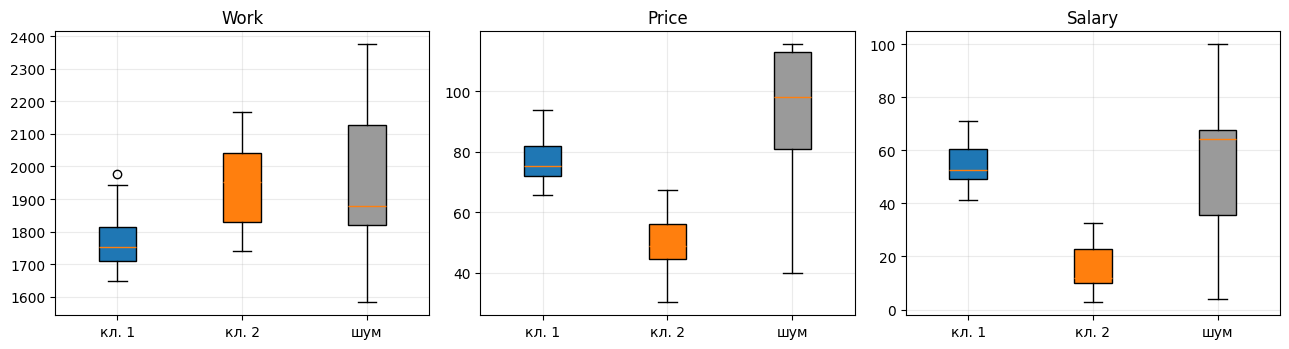

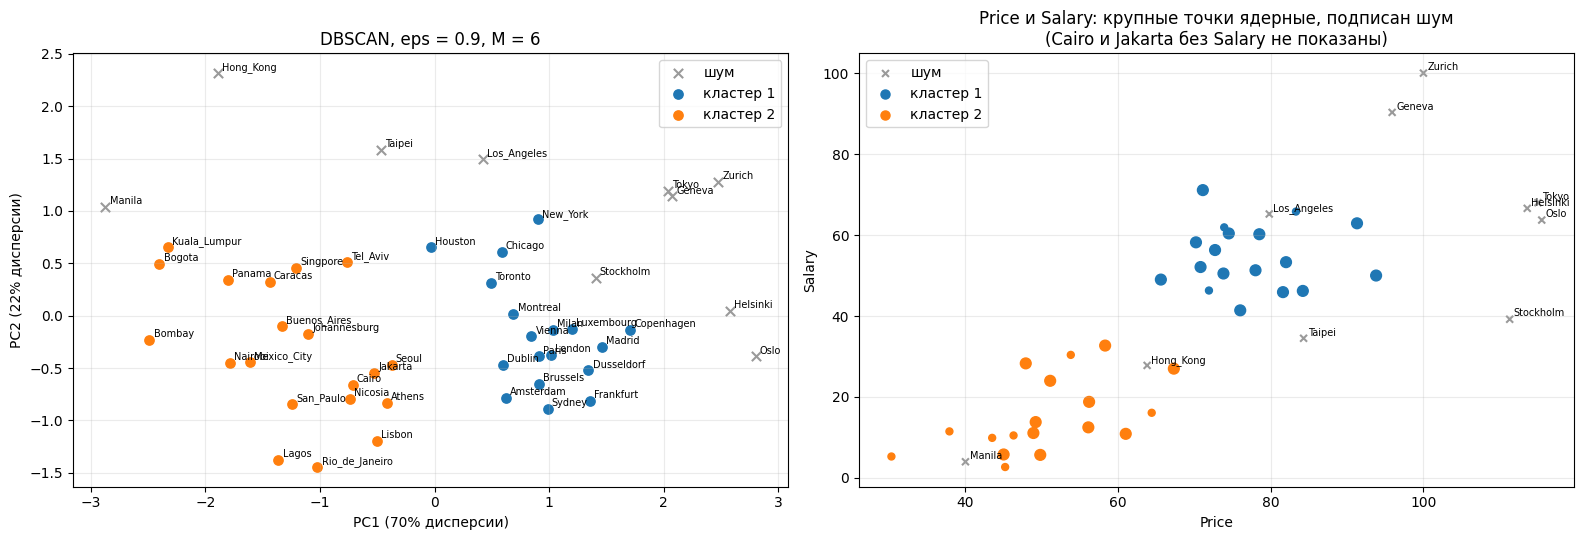

In [17]:
display(profile(X, db_labels).round(1))
plot_boxes(X, db_labels)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
P_db = plot_pca(Z, db_labels, X.index, f'DBSCAN, eps = {EPS}, M = {MIN_SAMPLES}', ax=axes[0])
for g in sorted(set(db_labels)):
    m = db_labels == g
    axes[1].scatter(X.loc[m, 'Price'], X.loc[m, 'Salary'], c=color(g), marker='x' if g == -1 else 'o',
                    s=np.where(core[m], 60, 25), label='шум' if g == -1 else f'кластер {g}')
for city in X.index[~clustered]:
    axes[1].annotate(city, (X.Price[city], X.Salary[city]), fontsize=7, xytext=(3, 2), textcoords='offset points')
axes[1].set(xlabel='Price', ylabel='Salary', title='Price и Salary: крупные точки ядерные, подписан шум\n(Cairo и Jakarta без Salary не показаны)')
axes[1].legend()
plt.tight_layout()
plt.show()

**Кластер 1 (18 городов, из них 15 ядерных):** дорогие города с высокими зарплатами и коротким рабочим годом. В среднем зарплата 55 % от цюрихской, цены 77 %, 1 777 часов (Paris, London, Frankfurt, New_York, Toronto).

**Кластер 2 (20 городов, из них 11 ядерных):** более дешёвые города с низкими зарплатами и длинным рабочим годом. В среднем зарплата 15 %, цены 50 %, 1 942 часа (Bogota, Bombay, Nairobi, Seoul).

Средние чуть ниже, чем в k-means, потому что крайние города ушли в шум: из первого кластера ушли Zurich, Geneva, Tokyo, Oslo, Stockholm и Helsinki (зарплаты и цены упали с 59 и 85 до 55 и 77), из второго ушли Hong_Kong, Manila и Taipei (рабочий год сократился с 1 988 до 1 942 часов). На ящиках с усами шум перекрывает оба кластера по всем признакам, это ещё один довод не считать его отдельной группой.

### 3D-иллюстрация окрестности радиуса `eps = 0.9`

В пространстве z-оценок видны все три признака без сжатия. Полупрозрачные сферы радиуса `eps = 0.9` показывают разницу между ядерным городом (`Paris`: внутри сферы плотная группа соседей) и шумом (`Tokyo`: сфера пустая).

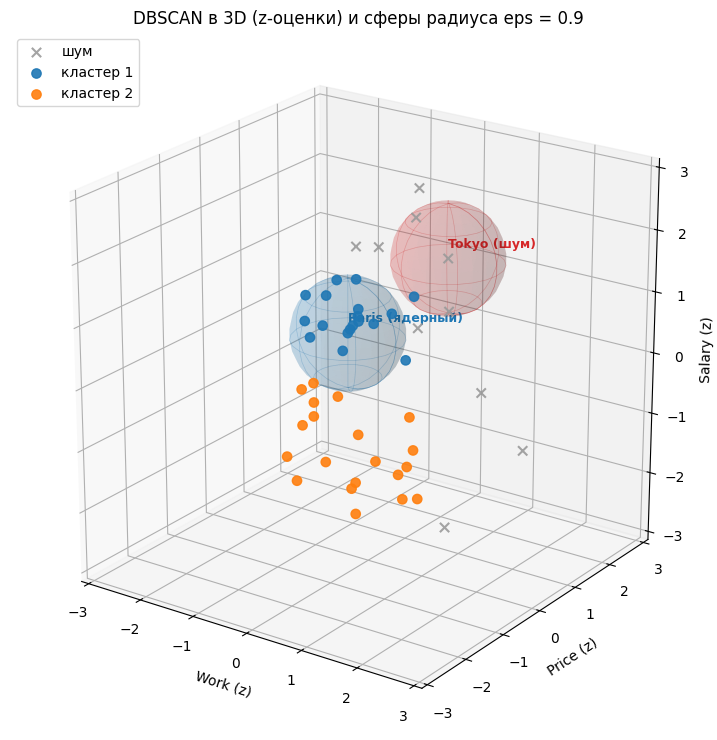

In [18]:
fig = plt.figure(figsize=(9, 7.5))
ax = fig.add_subplot(111, projection='3d')

for g in sorted(set(db_labels)):
    m = db_labels == g
    ax.scatter(Z[m, 0], Z[m, 1], Z[m, 2], c=color(g), s=45,
               marker='x' if g == -1 else 'o', alpha=0.9,
               label='шум' if g == -1 else f'кластер {g}')

u, v = np.mgrid[0:2 * np.pi:24j, 0:np.pi:16j]
sx, sy, sz = EPS * np.cos(u) * np.sin(v), EPS * np.sin(u) * np.sin(v), EPS * np.cos(v)

for city, col, tag in [('Paris', '#1f77b4', 'ядерный'), ('Tokyo', '#d62728', 'шум')]:
    cx, cy, cz = Z[X.index.get_loc(city)]
    ax.plot_surface(cx + sx, cy + sy, cz + sz, color=col, alpha=0.14, linewidth=0)
    ax.plot_wireframe(cx + sx, cy + sy, cz + sz, color=col, alpha=0.25, lw=0.5, rstride=4, cstride=4)
    ax.text(cx, cy, cz + 0.18, f'{city} ({tag})', fontsize=9, fontweight='bold', color=col)

lim = np.abs(Z).max() + 0.2
ax.set(xlim=(-lim, lim), ylim=(-lim, lim), zlim=(-lim, lim),
       xlabel='Work (z)', ylabel='Price (z)', zlabel='Salary (z)',
       title=f'DBSCAN в 3D (z-оценки) и сферы радиуса eps = {EPS}')
ax.set_box_aspect([1, 1, 1])
ax.view_init(elev=22, azim=-55)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 3.4. Кто попал в шум и почему

У каждого шумового города в радиусе 0.9 меньше 6 соседей, и рядом с ним нет ядерного. Смотрю на расстояние до ближайшего ядерного города и экстремальные признаки (`|z| ≥ 1.5`).

In [19]:
from sklearn.neighbors import NearestNeighbors

zdf = pd.DataFrame(Z, index=X.index, columns=FEATURES)
dist_to_core = NearestNeighbors(n_neighbors=1).fit(Z[core]).kneighbors(Z)[0][:, 0]
noise = X[~clustered].join(zdf[~clustered].round(2).add_prefix('z_'))
noise['до ближайшего ядерного'] = dist_to_core[~clustered].round(2)
noise['экстремальный признак'] = [', '.join(f'{f} {"↑" if v > 0 else "↓"}' for f, v in row.items() if abs(v) >= 1.5) or 'нет'
                                  for _, row in zdf[~clustered].iterrows()]
noise.sort_values('до ближайшего ядерного', ascending=False)

,Work,Price,Salary,z_Work,z_Price,z_Salary,до ближайшего ядерного,экстремальный признак
City,,,,,,,,
Hong_Kong,2375.0,63.8,27.8,2.94,-0.23,-0.50,1.97,Work ↑
Zurich,1868.0,100.0,100.0,-0.06,1.44,2.51,1.83,Salary ↑
Geneva,1880.0,95.9,90.3,0.01,1.25,2.11,1.51,Salary ↑
Tokyo,1880.0,115.0,68.0,0.01,2.14,1.18,1.48,Price ↑
Oslo,1583.0,115.5,63.7,-1.75,2.16,1.00,1.38,"Work ↓, Price ↑"
Manila,2268.0,40.0,4.0,2.31,-1.34,-1.49,1.27,Work ↑
Los_Angeles,2068.0,79.8,65.2,1.12,0.51,1.06,1.19,нет
Taipei,2145.0,84.3,34.5,1.58,0.72,-0.22,1.15,Work ↑
Helsinki,1667.0,113.6,66.6,-1.25,2.08,1.12,1.09,Price ↑


Шумовые города распадаются на четыре типа крайних наблюдений:

* самые высокие зарплаты: Zurich и Geneva (Salary 90–100);
* очень высокие цены: Oslo, Tokyo, Helsinki, Stockholm (Price 111–116);
* длинный рабочий год: Hong_Kong (2 375 часов), Manila (2 268) и Taipei (2 145);
* необычное сочетание у Los_Angeles: высокая зарплата при длинном рабочем годе (ни один признак по отдельности не экстремален, но рядом нет плотной группы).

Это фон вокруг двух плотных кластеров, а не третий кластер и не признак ошибок в данных. Состав шума согласуется с ЛР1, где single linkage по одному отрезал Hong_Kong, Tokyo и пару Geneva и Zurich.

## 3.5. Устойчивость шума при соседних параметрах

In [20]:
for eps, ms in [(0.80, 6), (0.85, 6), (0.95, 6), (0.9, 5), (0.9, 7), (0.9, 8)]:
    other = run_dbscan(Z, eps, ms)[0] == -1
    print(f'eps = {eps}, M = {ms}: в шум добавились {list(X.index[other & clustered])}, '
          f'ушли из шума {list(X.index[~other & ~clustered])}')

eps = 0.8, M = 6: в шум добавились ['Bombay', 'Cairo', 'Tel_Aviv'], ушли из шума []
eps = 0.85, M = 6: в шум добавились ['Bombay'], ушли из шума []
eps = 0.95, M = 6: в шум добавились [], ушли из шума ['Los_Angeles']
eps = 0.9, M = 5: в шум добавились [], ушли из шума ['Manila']
eps = 0.9, M = 7: в шум добавились [], ушли из шума []
eps = 0.9, M = 8: в шум добавились ['Bombay'], ушли из шума []


Восемь городов остаются шумом при всех соседних параметрах: Zurich, Geneva, Tokyo, Oslo, Helsinki, Stockholm, Hong_Kong, Taipei. Статус Los_Angeles и Manila условный: Los_Angeles входит в первый кластер при `eps = 0.95`, Manila во второй при `M = 5`. При меньшем радиусе в шум добавляются пограничные Bombay, Cairo и Tel_Aviv; при `M = 8` в шум уходит Bombay.

## 3.6. Проверка другой стандартизации для DBSCAN: приведение к `[0, 1]`

На шкале `[0, 1]` расстояния другие, поэтому `eps` подбираю заново при `M = 6`.

In [21]:
display(pd.DataFrame([{'eps': eps, **describe_dbscan(minmax, eps, MIN_SAMPLES, ward_labels)}
                      for eps in np.round(np.arange(0.14, 0.31, 0.01), 2)])
        .set_index('eps')[['clusters', 'размеры', 'noise', 'как Ward']].T)

EPS_MM = 0.22
db_mm = relabel_by_salary(run_dbscan(minmax, EPS_MM, MIN_SAMPLES)[0], X)
display(pd.crosstab(pd.Series(db_labels, name=f'z-оценки, eps = {EPS}'),
                    pd.Series(db_mm, name=f'[0, 1], eps = {EPS_MM}')))
print('Шум только в одном из двух решений:', sorted(set(X.index[db_labels == -1]) ^ set(X.index[db_mm == -1])))
literal = run_dbscan(minmax, EPS, MIN_SAMPLES)[0]
print(f'Тот же радиус {EPS} на шкале [0, 1]: кластеров {len(set(literal) - {-1})}, шум {(literal == -1).sum()}')

eps,0.14,0.15,0.16,0.17,0.18,0.19,0.20,0.21,0.22,0.23,0.24,0.25,0.26,0.27,0.28,0.29,0.30
clusters,1,2,2,2,3,2,2,2,2,2,2,1,1,1,1,1,1
размеры,12,12 / 6,13 / 7,15 / 10,16 / 5 / 12,18 / 18,19 / 18,19 / 20,19 / 20,19 / 20,19 / 20,39,39,42,43,43,43
noise,36,30,28,23,15,12,11,9,9,9,9,9,9,6,5,5,5
как Ward,False,True,True,True,False,True,True,True,True,True,True,False,False,False,False,False,False


"[0, 1], eps = 0.22",-1,1,2
"z-оценки, eps = 0.9",,,
-1,9,1,0
1,0,18,0
2,0,0,20


Шум только в одном из двух решений: ['Los_Angeles']
Тот же радиус 0.9 на шкале [0, 1]: кластеров 1, шум 0


Буквально перенести `eps = 0.9` на шкалу `[0, 1]` нельзя: все 48 городов сливаются в один кластер. При подборе заново плато возникает при `eps = 0.19–0.24`; в середине (`0.22`) получаются кластеры 19 / 20 и 9 городов шума. От основного решения на z-оценках оно отличается одним пограничным городом: Los_Angeles входит в первый кластер.

---
# Часть 3. Сравнение ЛР1–3 и итоговые выводы

Номера кластеров разных методов напрямую сравнивать нельзя, поэтому сравниваю состав групп таблицами сопряжённости и ARI: Ward (ЛР1), k-means (ЛР2) и DBSCAN (ЛР3).

In [22]:
ward_labels3 = relabel_by_salary(fcluster(ward_tree, t=3, criterion='maxclust'), X)

display(pd.crosstab(pd.Series(km_labels, name='k-means (k = 2)'), pd.Series(ward_labels, name='Ward (k = 2)')))
display(pd.crosstab(pd.Series(db_labels, name='DBSCAN'), pd.Series(ward_labels, name='Ward (k = 2)')))
print('ARI k-means и Ward (k = 2, 48 городов):', round(adjusted_rand_score(km_labels, ward_labels), 3))
print('ARI DBSCAN и Ward / k-means (38 городов без шума):',
      round(adjusted_rand_score(db_labels[clustered], ward_labels[clustered]), 3), '/',
      round(adjusted_rand_score(db_labels[clustered], km_labels[clustered]), 3))
for g in (1, 2):
    print(f'Из кластера {g} Ward/k-means в шум DBSCAN ушли:', ', '.join(X.index[~clustered & (ward_labels == g)]))

display(pd.crosstab(pd.Series(km_labels3, name='k-means (k = 3)'), pd.Series(ward_labels3, name='Ward (k = 3)')))
print('ARI k-means и Ward при k = 3:', round(adjusted_rand_score(km_labels3, ward_labels3), 3))
match = pd.crosstab(km_labels3, ward_labels3).idxmax(axis=1)
movers = X.index[match[km_labels3].to_numpy() != ward_labels3]
print('Перебежчики при k = 3:', ', '.join(movers))
display(X.loc[movers])

km_same_subset = quality(Z[clustered], km_labels[clustered])
pd.DataFrame({
    f'Ward / k-means, все {len(X)} городов': km_scores,
    f'k-means, те же {n_clustered} городов': km_same_subset,
    f'DBSCAN, {n_clustered} городов без шума': db_scores,
}).T.round(3)

Ward (k = 2),1,2
k-means (k = 2),,
1,25,0
2,0,23


Ward (k = 2),1,2
DBSCAN,,
-1,7,3
1,18,0
2,0,20


ARI k-means и Ward (k = 2, 48 городов): 1.0
ARI DBSCAN и Ward / k-means (38 городов без шума): 1.0 / 1.0
Из кластера 1 Ward/k-means в шум DBSCAN ушли: Geneva, Helsinki, Los_Angeles, Oslo, Stockholm, Tokyo, Zurich
Из кластера 2 Ward/k-means в шум DBSCAN ушли: Hong_Kong, Manila, Taipei


Ward (k = 3),1,2,3
k-means (k = 3),,,
1,25,0,0
2,0,0,10
3,0,9,4


ARI k-means и Ward при k = 3: 0.857
Перебежчики при k = 3: Buenos_Aires, Johannesburg, Mexico_City, Nairobi


,Work,Price,Salary
City,,,
Buenos_Aires,1971.0,56.1,12.5
Johannesburg,1945.0,51.1,24.0
Mexico_City,1944.0,49.8,5.7
Nairobi,1958.0,45.0,5.8


,silhouette,CH,DB
"Ward / k-means, все 48 городов",0.454,53.742,0.844
"k-means, те же 38 городов",0.501,55.876,0.734
"DBSCAN, 38 городов без шума",0.501,55.876,0.734


* **Согласие трёх методов при k = 2:** Ward и k-means дают идентичное разбиение всех 48 городов (ARI = 1). DBSCAN не переносит ни одного города между группами, а лишь отправляет 10 крайних городов в шум (7 из первого кластера и 3 из второго); на оставшихся 38 городах ARI = 1 с обоими методами. Совпадение трёх алгоритмов с разной логикой (слияние снизу вверх, центры, плотность) и устойчивость к шкале `[0, 1]` усиливают доверие к двум группам.
* **Перебежчики при k = 3:** между Ward и k-means расходятся 4 города (ARI 0.857): Buenos_Aires, Johannesburg, Mexico_City и Nairobi. Их рабочие часы (1 944–1 971) лежат ровно в пограничной зоне между двумя частями второго кластера. Это дополнительный довод в пользу k = 2.
* **Сравнение метрик:** silhouette DBSCAN (0.501) нельзя напрямую сравнивать с 0.454 у Ward и k-means, потому что он посчитан на 38 городах без шума. На тех же 38 городах k-means даёт ровно те же 0.501 / CH 55.9 / DB 0.734.

## Итоговые выводы

1. **ЛР2 (k-means):** после заполнения пропусков медианой и стандартизации (без неё 96.5 % дисперсии на Work) излом «каменистой осыпи» W(k) указывает на **k = 2** (падение W на 54 %, дальше не больше 24 %; silhouette 0.454 и CH 53.7 дополнительно подтверждают). Выделяются 25 дорогих высокооплачиваемых городов (Salary 59, Price 85, 1 789 ч) и 23 более дешёвых города с низкими зарплатами и длинным рабочим годом (16, 51, 1 988 ч). Из-за локальных минимумов необходимо много запусков (`n_init = 50`).
2. **ЛР3 (DBSCAN):** пошаговый подбор по одному параметру привёл к **`eps = 0.9`, `M = 6`** из середины плато `eps = 0.80–0.95` и `M = 5–8`. Силуэт для подбора не подходит (максимум 0.728 при 63 % шума). Получились те же две плотные группы (18 и 20 городов) и 10 шумовых городов (21 %): крайние по зарплатам, ценам, часам работы или их сочетанию.
3. **Общий итог ЛР1–3:** все три метода находят одни и те же две группы (ARI = 1 на общих городах), а деление на три кластера неустойчиво по границе и по способу стандартизации. Для полной типологии всех городов удобнее k-means (каждый кластер задаётся центром в исходных единицах) и Ward (дерево слияний), а DBSCAN полезен как дополнение для выделения нетипичных городов.

Ограничения: 48 городов, данные 1991 года; у Cairo и Jakarta заполнены 2 из 3 признаков; Price и Salary сильно коррелируют (r = 0.80); на 48 объектах плотность в DBSCAN оценивается грубо, поэтому статус пограничных Los_Angeles и Manila зависит от точных параметров.

In [23]:
def save_results(folder, X, Z, P, labels, selection, summary):
    # сохраняю разбиение, таблицу подбора и параметры с метриками
    out = Path(folder)
    out.mkdir(exist_ok=True)
    z = {f'z_{f}': Z[:, i] for i, f in enumerate(FEATURES)}
    X.assign(imputed=X.isna().any(axis=1), **z, PC1=P[:, 0], PC2=P[:, 1], cluster=labels).to_csv(out / 'assignments.csv')
    selection.to_csv(out / 'selection.csv', index=False)
    (out / 'summary.json').write_text(json.dumps({'n': len(X)} | summary, ensure_ascii=False, indent=2, default=float))


save_results('results_lab02', X, Z, P, km_labels, km_grid, {
    'params': {'k': K, 'init': 'k-means++', 'n_init': 50, 'max_iter': 300, 'random_state': 42},
    'rationale': 'излом «каменистой осыпи» W(k): 1 → 2 даёт −54 %, дальше не больше −24 %; silhouette и CH дополнительно тоже за k = 2',
    'clusters': K, 'noise': 0, 'metrics': km_scores, 'metrics_n': len(X),
})

save_results('results_lab03', X, Z, P_db, db_labels,
             db_grid[['min_samples', 'eps', 'clusters', 'noise', 'min_size', 'silhouette']], {
    'params': {'eps': EPS, 'min_samples': MIN_SAMPLES, 'metric': 'euclidean'},
    'rationale': 'eps = 0.9 из середины плато 0.80–0.95 при M = 6: 2 кластера, шум от 13 до 9 городов; '
                 'при eps = 0.9 M от 5 до 8 дают те же две группы, меняется только состав шума; '
                 'на городах вне шума состав совпадает с Ward',
    'clusters': len(set(db_labels) - {-1}), 'noise': int((~clustered).sum()), 'noise_cities': X.index[~clustered].tolist(),
    'metrics': db_scores, 'metrics_n': n_clustered, 'kmeans_same_subset_metrics': km_same_subset,
})